# PySpark Fundamentals: Shuffles, Joins, Skew, and Tuning

**What you'll learn**

- When you actually need Spark — an honest sizing framework (pandas/DuckDB now handle
  tens of GB on one machine; Spark earns its complexity at TB scale, on an existing
  lakehouse, or for distributed pipelines).
- The architecture you need for interviews: driver/executors, lazy evaluation, DAGs,
  stages and tasks — plus how to read a real `.explain()` plan and spot every shuffle.
- A pandas → PySpark phrasebook (`select`/`filter`/`groupBy`/`join`/window/`withColumn`)
  and Spark SQL interop, each result cross-checked against pandas.
- Sort-merge vs broadcast joins: the same join executed both ways, with plans and wall
  times compared, plus what AQE (adaptive query execution) changes at runtime.
- Skew end-to-end: build a whale-key distribution, *measure* the straggler-task pattern,
  fix it with key salting (full implementation), and see AQE's automatic skew splitting.
- `repartition` vs `coalesce`, when caching helps vs wastes memory, and the real cost
  of Python UDFs (built-in vs `pandas_udf` vs Arrow UDF vs pickled UDF, benchmarked).

**Why it matters in interviews**

- "A job sits at 199/200 tasks for an hour — diagnose it" is a canonical senior
  big-data screen. The answer (skew, task-time distributions, salting, AQE) is exactly
  what this notebook demonstrates with measurements.
- "Walk me through what happens when you join two large tables" tests whether you
  understand shuffles physically, not just the API.
- "Why is your PySpark job slow?" usually reduces to one of four things covered here:
  an avoidable shuffle, a skewed key, a missing broadcast, or a Python UDF.
- Sizing questions ("would you use Spark for this?") separate seniors from juniors —
  the strong answer is *not* always-Spark.

SQL fundamentals live in `01_advanced_sql_duckdb.ipynb` and product-analytics SQL in
`02_sql_product_analytics.ipynb`; distributed ML on top of these foundations is
`04_sparkml_pipeline.ipynb`.

## 1. Do you actually need Spark? (the senior answer)

The honest sizing conversation, circa 2026:

| working set | tool | why |
|---|---|---|
| < ~10 GB | pandas / Polars | fits in RAM on a laptop; fastest iteration loop |
| ~10–100+ GB | DuckDB / Polars on one beefy box | columnar, out-of-core, vectorized; a single `r6i.8xlarge` has 256 GB RAM |
| TB-scale, or growing that way | Spark (or a warehouse) | data no longer fits one machine's RAM+disk budget |
| data already in a lakehouse (Delta/Iceberg) with Spark infra | Spark | the marginal cost of Spark is near zero; fighting the platform costs more |
| pipelines that must scale elastically / run distributed anyway | Spark | scheduling, retries, and locality are solved problems there |

What distribution *costs* you: serialization at every boundary, network shuffles,
slower iteration (cluster startup, JVM), and a much bigger debugging surface. A senior
candidate leads with this trade-off. "We profiled it; the working set was 40 GB, so we
used DuckDB on one node and cut the pipeline from 40 minutes to 4" is a stronger
interview answer than reflexively reaching for a cluster.

Everything below runs Spark in **`local[2]`** mode (driver + 2 worker threads, one JVM,
UI disabled) on deliberately modest data. Two consequences to keep in mind:

1. **Timings are illustrative, not absolute.** They demonstrate *relative* effects
   (broadcast vs shuffle, UDF overhead, stragglers); exact numbers vary with machine load.
2. **Local mode understates shuffle pain.** A local "shuffle" is memory/disk traffic in
   one JVM. On a real cluster it is network I/O + disk on many machines — every shuffle
   effect you see here is *worse* in production.

(Session startup prints some JVM noise — `JAVA_TOOL_OPTIONS`, hostname warnings.
That is environment noise, not a Spark problem.)

In [1]:
import contextlib
import io
import statistics
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark import TaskContext
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.functions import pandas_udf, spark_partition_id
from pyspark.sql.types import DoubleType

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

spark = (
    SparkSession.builder
    .master("local[2]")                                   # driver + 2 worker threads, one JVM
    .appName("pyspark-fundamentals")
    .config("spark.ui.enabled", "false")                  # no web UI in this environment
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.driver.memory", "3g")
    .config("spark.sql.shuffle.partitions", "8")          # default 200 is silly for local data
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext


def spark_time(fn, reps=3):
    """Median wall time of an action over `reps` runs (median tames scheduler noise)."""
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), [round(t, 2) for t in times]


def plan_of(df) -> str:
    """Capture df.explain() output as a string (public API only)."""
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain()
    return buf.getvalue()


print(f"Spark {spark.version} | master={sc.master} | "
      f"shuffle.partitions={spark.conf.get('spark.sql.shuffle.partitions')} | "
      f"AQE={spark.conf.get('spark.sql.adaptive.enabled')}")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/root/.ccr/java-truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12 -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=42545 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|anthropic.com|*.anthropic.com|*.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/root/.ccr/java-truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12 -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=42545 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|anthropic.com|*.anthropic.com|*.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/07/20 10:12:04 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/07/20 10:12:04 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/07/20 10:12:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master=local[2] | shuffle.partitions=8 | AQE=true


## 2. Architecture in ten minutes

The mental model an interviewer expects, bottom to top:

- **Driver**: runs your Python program, holds the SparkSession, builds the query plan,
  schedules work. `collect()`/`toPandas()` pull data *into* this single process — the
  classic OOM site.
- **Executors**: JVM processes on worker nodes that hold data partitions and run tasks.
  Python UDFs additionally fork Python worker processes next to each executor.
- **Lazy evaluation**: transformations (`select`, `filter`, `join`, …) only build a
  logical plan. Nothing executes until an **action** (`count`, `collect`, `write`, …).
  Catalyst then optimizes the whole plan end-to-end — that is *why* laziness exists.
- **Job → stages → tasks**: each action launches a job; the job is cut into **stages at
  shuffle boundaries**; each stage runs one **task per partition**. "199/200 tasks done"
  means one *task* (one partition) in a stage is the straggler.

**Narrow vs wide transformations** — the single most useful thing to memorize:

| narrow (no shuffle; pipelined in one stage) | wide (shuffle; new stage) |
|---|---|
| `select`, `withColumn`, `drop`, `cast` | `groupBy(...).agg(...)` (the exchange is on grouped keys) |
| `filter` / `where`, `sample`, `limit` (mostly) | `join` (unless broadcast) |
| `union` (concatenates partitions) | `distinct`, `dropDuplicates` |
| map-side *partial* aggregation | `orderBy` / `sort` (range repartition) |
| `coalesce` (merges partitions in place) | `repartition` (full shuffle) |
| broadcast join (small side shipped to all) | `Window.partitionBy(...)` |

A shuffle = every input partition writes key-hashed blocks, every output partition
reads its blocks from *all* inputs. It's all-to-all data movement — the expensive thing
in distributed compute, and the thing every tuning trick tries to avoid, shrink, or balance.

In [2]:
# Two tables, generated INSIDE the JVM (spark.range + seeded rand -> deterministic,
# and no driver->executor serialization cost):
#   orders    : 1.5M rows (order_id, customer_id, amount, channel)
#   customers : 200K rows  (customer_id, segment, region)
N_ORDERS, N_CUST = 1_500_000, 200_000


def pick(col_expr, options, salt):
    """Deterministically map a column to one of `options` via hashing."""
    arr = F.array(*[F.lit(o) for o in options])
    idx = (F.hash(col_expr, F.lit(salt)) % len(options) + len(options)) % len(options)
    return F.element_at(arr, idx + 1)


orders_lineage = (
    spark.range(0, N_ORDERS, 1, 8)                        # 8 partitions
    .withColumnRenamed("id", "order_id")
    .withColumn("customer_id", (F.hash("order_id") % N_CUST + N_CUST) % N_CUST)
    .withColumn("amount", F.round(-F.log(F.rand(seed=42)) * 60.0, 2))   # ~Exp, mean $60
    .withColumn("channel", pick(F.col("order_id"), ["web", "app", "store"], 1))
)
orders = orders_lineage.cache()

customers = (
    spark.range(0, N_CUST, 1, 4)
    .withColumnRenamed("id", "customer_id")
    .withColumn("segment", pick(F.col("customer_id"), ["consumer", "smb", "enterprise"], 2))
    .withColumn("region", pick(F.col("customer_id"), ["amer", "emea", "apac"], 3))
).cache()

t0 = time.perf_counter()
n_orders, n_cust = orders.count(), customers.count()      # actions: materialize both caches
print(f"orders: {n_orders:,} rows in {orders.rdd.getNumPartitions()} partitions | "
      f"customers: {n_cust:,} rows  (built + cached in {time.perf_counter()-t0:.1f}s)")
orders.show(3)

orders: 1,500,000 rows in 8 partitions | customers: 200,000 rows  (built + cached in 5.9s)


+--------+-----------+------+-------+
|order_id|customer_id|amount|channel|
+--------+-----------+------+-------+
|       0|      75805| 28.76|    app|
|       1|      80669| 40.45|    web|
|       2|      72728|  11.0|  store|
+--------+-----------+------+-------+
only showing top 3 rows


In [3]:
# Lazy evaluation, measured: building a plan is cheap; the action does the work.
def build_pipeline():
    return (
        orders.filter(F.col("amount") > 30)
        .withColumn("amount_bucket", (F.col("amount") / 50).cast("int"))
        .groupBy("channel", "amount_bucket")
        .agg(F.count("*").alias("n"), F.avg("amount").alias("avg_amount"))
    )


_ = build_pipeline()          # warm up py4j / expression-parsing paths once
t0 = time.perf_counter()
pipeline = build_pipeline()   # 4 chained transformations
t_define = time.perf_counter() - t0

t0 = time.perf_counter()
n_groups = pipeline.count()
t_run = time.perf_counter() - t0
print(f"defining 4 chained transformations: {t_define*1000:.1f} ms  (no job ran)")
print(f"running .count() action:            {t_run:.2f} s   ({n_groups} result groups)")

defining 4 chained transformations: 65.7 ms  (no job ran)
running .count() action:            1.42 s   (48 result groups)


### Reading a real `.explain()` plan

Read physical plans **bottom-up**. The things to find in the plan below:

- **`InMemoryTableScan` / `Range`** at the bottom: the data source (here our cached table).
- **`Filter`** sits directly on the scan — Catalyst pushed it below the aggregation.
- **`HashAggregate(... functions=[partial_...])`** *below* the `Exchange`: map-side
  **partial aggregation**. Each partition pre-aggregates locally, so only compact
  partial states get shuffled, not raw rows. (This is why plain `groupBy().sum()` on a
  skewed key usually does *not* create a straggler — remember this for section 6.)
- **`Exchange hashpartitioning(...)`** = **the shuffle**. Count the `Exchange` nodes and
  you have counted the stage boundaries. One `Exchange` here → 2 stages.
- **`HashAggregate(... functions=[...])`** above it: the final merge of partial states.
- `*(n)` prefixes = whole-stage code generation: Spark fused those operators into one
  compiled loop.

(AQE is disabled for just this one print — it wraps plans in `AdaptiveSparkPlan` and
we want the raw structure first. AQE returns in section 5.)

In [4]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
pipeline.explain()
n_shuffles = plan_of(pipeline).count("Exchange")
print(f"Exchange nodes in plan: {n_shuffles}  ->  {n_shuffles + 1} stages for this job")
spark.conf.set("spark.sql.adaptive.enabled", "true")

== Physical Plan ==
*(2) HashAggregate(keys=[channel#4, amount_bucket#417], functions=[count(1), avg(amount#3)])
+- Exchange hashpartitioning(channel#4, amount_bucket#417, 8), ENSURE_REQUIREMENTS, [plan_id=288]
   +- *(1) HashAggregate(keys=[channel#4, amount_bucket#417], functions=[partial_count(1), partial_avg(amount#3)])
      +- *(1) Project [amount#3, channel#4, cast((amount#3 / 50.0) as int) AS amount_bucket#417]
         +- *(1) Filter (isnotnull(amount#3) AND (amount#3 > 30.0))
            +- InMemoryTableScan [amount#3, channel#4], [isnotnull(amount#3), (amount#3 > 30.0)]
                  +- InMemoryRelation [order_id#1L, customer_id#2, amount#3, channel#4], StorageLevel(disk, memory, deserialized, 1 replicas)
                        +- *(1) Project [order_id#1L, customer_id#2, amount#3, element_at([web,app,store], ((((hash(order_id#1L, 1, 42) % 3) + 3) % 3) + 1), None, true) AS channel#4]
                           +- *(1) Project [id#0L AS order_id#1L, (((hash(id#0L, 42) % 

## 3. pandas → PySpark phrasebook

The API mapping is mostly mechanical; what changes is the *execution model* (lazy,
distributed, no index, no implicit ordering). Phrasebook on a small clickstream table —
every result is cross-checked against pandas, a habit worth keeping whenever you port
pipeline logic.

| pandas | PySpark |
|---|---|
| `df[["a", "b"]]` | `df.select("a", "b")` |
| `df[df.a > 0]` | `df.filter(F.col("a") > 0)` |
| `df.assign(c=...)` | `df.withColumn("c", ...)` |
| `df.groupby("k").agg(x=("v", "mean"))` | `df.groupBy("k").agg(F.avg("v").alias("x"))` |
| `df.merge(dim, on="k", how="left")` | `df.join(dim, "k", "left")` |
| `df.sort_values("v").groupby("k").head(2)` | `Window.partitionBy("k").orderBy(...)` + `row_number` |
| `df["v"].cumsum()` (per group) | `F.sum("v").over(w.rowsBetween(unboundedPreceding, 0))` |
| `df.drop_duplicates(["k"])` | `df.dropDuplicates(["k"])` (nondeterministic *which* row survives!) |

In [5]:
# Small product-analytics table built in pandas (realistic route: prototype data in
# pandas, then hand off to Spark).
N_EV, N_USERS = 60_000, 5_000
events_pd = pd.DataFrame({
    "event_id": np.arange(N_EV),
    "user_id": rng.integers(1, N_USERS + 1, N_EV),
    "event_ts": pd.Timestamp("2025-06-01")
                + pd.to_timedelta(rng.integers(0, 30 * 24 * 3600, N_EV), unit="s"),
    "event_type": rng.choice(["view", "cart", "purchase"], N_EV, p=[0.80, 0.15, 0.05]),
    "value": np.round(rng.gamma(2.0, 15.0, N_EV), 2),
})
events = spark.createDataFrame(events_pd)   # Arrow-accelerated because we enabled it in setup
events.printSchema()

root
 |-- event_id: long (nullable = true)
 |-- user_id: long (nullable = true)
 |-- event_ts: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- value: double (nullable = true)



In [6]:
# --- select / filter / withColumn -------------------------------------------------
# pandas: ev = events_pd[events_pd.event_type == "purchase"].assign(day=...)[cols]
purchases = (
    events.filter(F.col("event_type") == "purchase")
    .withColumn("day", F.to_date("event_ts"))
    .select("user_id", "day", "value")
)
purchases.show(3)

# --- groupBy / agg, checked against pandas ----------------------------------------
daily_sp = (
    purchases.groupBy("day")
    .agg(F.count("*").alias("n_purchases"), F.round(F.sum("value"), 2).alias("revenue"))
    .orderBy("day")
    .toPandas()
)
daily_pd = (
    events_pd.loc[events_pd.event_type == "purchase"]
    .assign(day=lambda d: d.event_ts.dt.date)
    .groupby("day", as_index=False)
    .agg(n_purchases=("value", "size"), revenue=("value", "sum"))
)
assert len(daily_sp) == len(daily_pd)
assert np.allclose(daily_sp["revenue"], daily_pd["revenue"].round(2))
print(f"groupBy/agg matches pandas on all {len(daily_sp)} days. First 3:")
print(daily_sp.head(3))

+-------+----------+-----+
|user_id|       day|value|
+-------+----------+-----+
|    461|2025-06-01|17.06|
|    650|2025-06-01|54.03|
|   3902|2025-06-20|34.89|
+-------+----------+-----+
only showing top 3 rows


groupBy/agg matches pandas on all 30 days. First 3:
          day  n_purchases  revenue
0  2025-06-01          107  3754.77
1  2025-06-02           95  2806.49
2  2025-06-03          103  2818.40


In [7]:
# --- window functions: top-2 purchases per user + running spend -------------------
# pandas: sort_values -> groupby.head(2) / groupby.cumsum
w_rank = Window.partitionBy("user_id").orderBy(F.desc("value"), F.asc("day"))
w_cum = (Window.partitionBy("user_id").orderBy("day", "value")
         .rowsBetween(Window.unboundedPreceding, Window.currentRow))

top2_sp = (
    purchases
    .withColumn("rk", F.row_number().over(w_rank))
    .filter(F.col("rk") <= 2)
    .withColumn("cum_spend", F.round(F.sum("value").over(w_cum), 2))
)
top2_pd = (
    events_pd.loc[events_pd.event_type == "purchase"]
    .sort_values(["user_id", "value"], ascending=[True, False])
    .groupby("user_id")
    .head(2)
)
sp_n, sp_sum = top2_sp.count(), top2_sp.agg(F.sum("value")).first()[0]
assert sp_n == len(top2_pd)
assert np.isclose(sp_sum, top2_pd["value"].sum(), rtol=1e-9)
print(f"top-2-per-user: {sp_n:,} rows, total value {sp_sum:,.2f} — matches pandas.")
top2_sp.show(4)

top-2-per-user: 2,900 rows, total value 88,635.40 — matches pandas.


+-------+----------+-----+---+---------+
|user_id|       day|value| rk|cum_spend|
+-------+----------+-----+---+---------+
|      3|2025-06-14|94.57|  1|    94.57|
|      3|2025-06-22|13.46|  2|   108.03|
|      7|2025-06-16|56.45|  1|    56.45|
|      7|2025-06-21| 6.24|  2|    62.69|
+-------+----------+-----+---+---------+
only showing top 4 rows


In [8]:
# --- join + Spark SQL interop via temp views --------------------------------------
users_pd = pd.DataFrame({
    "user_id": np.arange(1, N_USERS + 1),
    "country": rng.choice(["US", "DE", "GB", "BR"], N_USERS, p=[0.45, 0.25, 0.2, 0.1]),
})
users = spark.createDataFrame(users_pd)

events.createOrReplaceTempView("events")
users.createOrReplaceTempView("users")

# Same query, DataFrame API vs SQL — they compile to the SAME plan, so interviewers
# accept either; pick per readability.
df_api = (
    events.join(users, "user_id")
    .filter(F.col("event_type") == "purchase")
    .groupBy("country").agg(F.round(F.sum("value"), 2).alias("revenue"))
    .orderBy(F.desc("revenue"))
)
sql_api = spark.sql("""
    SELECT u.country, ROUND(SUM(e.value), 2) AS revenue
    FROM events e
    JOIN users u USING (user_id)
    WHERE e.event_type = 'purchase'
    GROUP BY u.country
    ORDER BY revenue DESC
""")
assert df_api.collect() == sql_api.collect()
print("DataFrame API and SQL agree:")
sql_api.show()

DataFrame API and SQL agree:


+-------+--------+
|country| revenue|
+-------+--------+
|     US|40142.02|
|     DE|22915.56|
|     GB| 18546.3|
|     BR| 9155.99|
+-------+--------+



## 4. Shuffles and joins: sort-merge vs broadcast

Joining `orders` (1.5M rows) to `customers` (200K) — the two physical strategies that
matter:

- **Sort-merge join (SMJ)**: shuffle *both* tables by the join key (`Exchange` on each
  side), sort each partition, merge. Cost: two full shuffles + sorts. This is the
  default for two large tables.
- **Broadcast hash join (BHJ)**: ship the *entire* small table to every executor once,
  build a hash map, stream the big table past it. **The big table never moves.** Cost:
  one broadcast of the small side; no shuffle of the fact table.

Spark auto-broadcasts below `spark.sql.autoBroadcastJoinThreshold` (default 10 MB of
*estimated* size); `F.broadcast(df)` / `/*+ BROADCAST(t) */` forces it when statistics
are missing or wrong (very common on fresh parquet reads with no stats).

For a clean A/B we temporarily disable AQE and auto-broadcast, then force each strategy
explicitly.

In [9]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")   # never auto-broadcast

smj_join = orders.join(customers, "customer_id")
bhj_join = orders.join(F.broadcast(customers), "customer_id")

print("--- sort-merge join plan (2 Exchanges + 2 Sorts: both sides shuffled) ---")
smj_join.explain()
print("--- broadcast join plan (BroadcastExchange only; orders never shuffled) ---")
bhj_join.explain()

--- sort-merge join plan (2 Exchanges + 2 Sorts: both sides shuffled) ---
== Physical Plan ==
*(4) Project [customer_id#2, order_id#1L, amount#3, channel#4, segment#27, region#28]
+- *(4) SortMergeJoin [cast(customer_id#2 as bigint)], [customer_id#26L], Inner
   :- *(2) Sort [cast(customer_id#2 as bigint) ASC NULLS FIRST], false, 0
   :  +- Exchange hashpartitioning(cast(customer_id#2 as bigint), 8), ENSURE_REQUIREMENTS, [plan_id=1257]
   :     +- *(1) Filter isnotnull(customer_id#2)
   :        +- InMemoryTableScan [order_id#1L, customer_id#2, amount#3, channel#4], [isnotnull(customer_id#2)]
   :              +- InMemoryRelation [order_id#1L, customer_id#2, amount#3, channel#4], StorageLevel(disk, memory, deserialized, 1 replicas)
   :                    +- *(1) Project [order_id#1L, customer_id#2, amount#3, element_at([web,app,store], ((((hash(order_id#1L, 1, 42) % 3) + 3) % 3) + 1), None, true) AS channel#4]
   :                       +- *(1) Project [id#0L AS order_id#1L, (((hash(i

== Physical Plan ==
*(1) Project [customer_id#2, order_id#1L, amount#3, channel#4, segment#27, region#28]
+- *(1) BroadcastHashJoin [cast(customer_id#2 as bigint)], [customer_id#26L], Inner, BuildRight, false, false
   :- *(1) Filter isnotnull(customer_id#2)
   :  +- InMemoryTableScan [order_id#1L, customer_id#2, amount#3, channel#4], [isnotnull(customer_id#2)]
   :        +- InMemoryRelation [order_id#1L, customer_id#2, amount#3, channel#4], StorageLevel(disk, memory, deserialized, 1 replicas)
   :              +- *(1) Project [order_id#1L, customer_id#2, amount#3, element_at([web,app,store], ((((hash(order_id#1L, 1, 42) % 3) + 3) % 3) + 1), None, true) AS channel#4]
   :                 +- *(1) Project [id#0L AS order_id#1L, (((hash(id#0L, 42) % 200000) + 200000) % 200000) AS customer_id#2, round((-ln(rand(42)) * 60.0), 2) AS amount#3]
   :                    +- *(1) Range (0, 1500000, step=1, splits=8)
   +- BroadcastExchange HashedRelationBroadcastMode(List(input[0, bigint, false])

In [10]:
def run_smj():
    smj_join.groupBy("segment").agg(F.sum("amount")).collect()


def run_bhj():
    bhj_join.groupBy("segment").agg(F.sum("amount")).collect()


t_smj, raw_smj = spark_time(run_smj)
t_bhj, raw_bhj = spark_time(run_bhj)
join_bench = pd.DataFrame({
    "strategy": ["sort-merge (shuffle both)", "broadcast (ship small side)"],
    "median_s": [round(t_smj, 2), round(t_bhj, 2)],
    "runs_s": [raw_smj, raw_bhj],
})
print(join_bench.to_string(index=False))
print(f"\nbroadcast speedup: {t_smj / t_bhj:.1f}x  "
      "(understated in local mode — a real cluster shuffles over the network)")

                   strategy  median_s            runs_s
  sort-merge (shuffle both)      1.85 [3.36, 1.8, 1.85]
broadcast (ship small side)      1.00 [1.38, 1.0, 0.92]

broadcast speedup: 1.9x  (understated in local mode — a real cluster shuffles over the network)


### What AQE changes

**Adaptive Query Execution** (on by default since Spark 3.2) re-optimizes the plan *at
stage boundaries* using the actual shuffle statistics it just observed:

1. **Coalesces small shuffle partitions** — the practical fix for the "200 tiny tasks"
   default (see the pitfalls section).
2. **Converts SMJ → broadcast at runtime** when a side turns out small (e.g. after a
   selective filter that Catalyst couldn't estimate).
3. **Splits skewed partitions** in joins — section 6.

So in modern Spark the *first* answer to "my join is slow" is often "check what AQE
already did in the final plan" (`AdaptiveSparkPlan isFinalPlan=true`), then tune what's
left. AQE stays on for the rest of the notebook except where we deliberately disable it
to expose a failure mode.

In [11]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10MB")

# AQE keeps the *initial* SMJ plan lazy; after running, the final plan shows what it did.
aqe_demo = orders.join(customers.filter(F.col("segment") == "enterprise"), "customer_id")
aqe_agg = aqe_demo.groupBy("region").agg(F.count("*").alias("n"))
aqe_agg.collect()
final_plan = plan_of(aqe_agg)
print("final plan is adaptive:", "isFinalPlan=true" in final_plan)
print("runtime broadcast happened:", "BroadcastHashJoin" in final_plan)

final plan is adaptive: True
runtime broadcast happened: True


## 5. Skew: the straggler problem

Real keys are Zipfian: one merchant is Amazon, one `user_id` is the logged-out bucket,
one `device_id` is `"unknown"`. After a shuffle **all rows with the same key land in the
same partition**, so one task carries most of the stage. The job "finishes" at 199/200
tasks and then sits there — CPU idle everywhere except one executor.

Two important nuances a senior candidate should volunteer:

- Plain algebraic aggregations (`sum`, `count`, `avg`) usually survive skew fine thanks
  to map-side partial aggregation (section 2). Skew bites on **joins**, **windows over
  the skewed key**, and non-algebraic aggs like `collect_list`.
- The whale key is often *garbage* (NULL, `-1`, `"unknown"`). The best fix can be to
  filter it out or handle it separately, not to engineer around it.

We build a payments table where **one merchant carries ~90% of transactions**, then
join it to a merchant dimension with SMJ forced (AQE off, no broadcast — on a real
cluster the dimension might be another fact table too big to broadcast).

In [12]:
N_TX, N_MERCH, WHALE_SHARE = 1_000_000, 2_000, 0.90

tx = (
    spark.range(0, N_TX, 1, 8)
    .withColumnRenamed("id", "tx_id")
    .withColumn(
        "merchant_id",
        F.when(F.rand(seed=7) < WHALE_SHARE, F.lit(0))    # merchant 0 = the whale
         .otherwise((F.hash("tx_id") % (N_MERCH - 1) + (N_MERCH - 1)) % (N_MERCH - 1) + 1),
    )
    .withColumn("amount", F.round(-F.log(F.rand(seed=8)) * 40.0, 2))
).cache()

merchants = (
    spark.range(0, N_MERCH, 1, 2)
    .withColumnRenamed("id", "merchant_id")
    .withColumn("category", pick(F.col("merchant_id"), ["retail", "food", "travel", "digital"], 4))
).cache()

tx.count(), merchants.count()
top_keys = tx.groupBy("merchant_id").count().orderBy(F.desc("count")).limit(3).toPandas()
whale_pct = 100 * top_keys["count"].iloc[0] / N_TX
print(f"top merchant holds {whale_pct:.1f}% of {N_TX:,} transactions:")
print(top_keys.to_string(index=False))

top merchant holds 90.0% of 1,000,000 transactions:
 merchant_id  count
           0 900293
         620     75
        1522     74


In [13]:
# The straggler pattern, measured. A shuffle hash-partitions rows by key; we reproduce
# exactly that with repartition(8, key), then time each partition's work (a sort, like
# the sort phase of SMJ) inside mapInPandas. This is per-TASK instrumentation — the same
# distribution the Spark UI would show as task durations.
def timed_partition(batches):
    t0 = time.perf_counter()
    pid = TaskContext.get().partitionId()
    frames = list(batches)
    n = 0
    if frames:
        block = pd.concat(frames)
        n = len(block)
        block.sort_values(["merchant_id", "amount"], inplace=True)     # SMJ-style sort
        _ = block["amount"].map(lambda v: np.log1p(v)).sum()           # per-row work
    yield pd.DataFrame({"pid": [pid], "n_rows": [n], "secs": [time.perf_counter() - t0]})


task_schema = "pid int, n_rows long, secs double"
skew_tasks = (
    tx.repartition(8, "merchant_id")
    .mapInPandas(timed_partition, schema=task_schema)
    .toPandas().sort_values("pid").reset_index(drop=True)
)
print(skew_tasks.to_string(index=False))
ratio_skew = skew_tasks.secs.max() / skew_tasks.secs.median()
print(f"\nstraggler: longest task = {ratio_skew:.0f}x the median task "
      f"({skew_tasks.n_rows.max():,} of {N_TX:,} rows in one partition)")

 pid  n_rows     secs
   0   13596 0.354640
   1   12749 0.354612
   2   13503 0.096988
   3   12507 0.087533
   4   11278 0.042650
   5   12013 0.012574
   6   12528 0.014991
   7  911826 1.314966

straggler: longest task = 14x the median task (911,826 of 1,000,000 rows in one partition)


### The fix: key salting

Split the whale key into `S` sub-keys so its rows spread over `S` partitions:

1. **Fact side**: add `salt = uniform_int(0, S)` — each whale row gets a random sub-key.
2. **Dimension side**: *replicate* each row `S` times, one per salt value (`explode`).
3. Join on `(key, salt)` — every fact row still finds exactly one dimension match, so
   the result is **row-for-row identical** to the plain join; the whale's work is now
   spread over `S` tasks.

Costs, which you should say out loud in an interview: the dimension side grows `S`-fold
(fine for a dimension, painful for a large table), the shuffled key is wider, and the
code is uglier. Salt only the keys that need it (you can salt just the whale and leave
the tail unsalted), and pick `S` around the number of cores you want the whale to occupy.

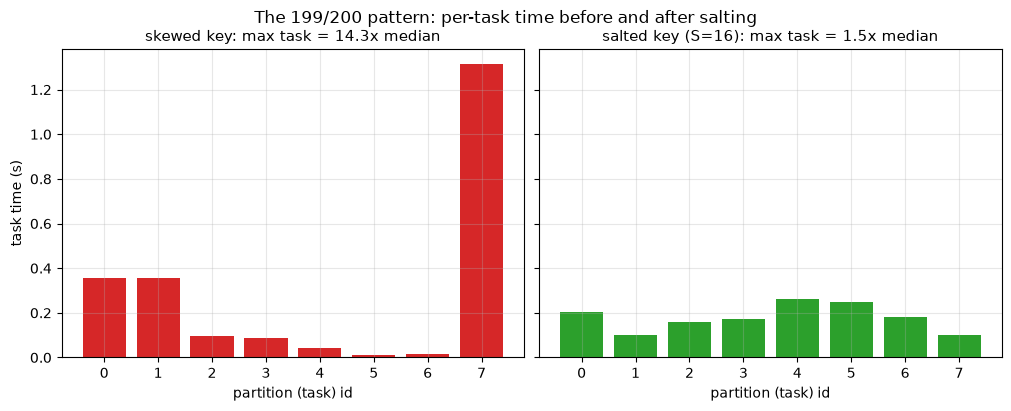

 pid  n_rows     secs
   0  125303 0.204836
   1   68282 0.101888
   2  125140 0.161116
   3  124631 0.170373
   4  181615 0.261844
   5  181236 0.247473
   6  124853 0.181480
   7   68940 0.102400


In [14]:
S = 16
tx_salted = tx.withColumn("salt", (F.rand(seed=99) * S).cast("int"))
merchants_salted = merchants.withColumn(
    "salt", F.explode(F.array(*[F.lit(i) for i in range(S)]))
)

salt_tasks = (
    tx_salted.repartition(8, "merchant_id", "salt")
    .mapInPandas(timed_partition, schema=task_schema)
    .toPandas().sort_values("pid").reset_index(drop=True)
)
ratio_salt = salt_tasks.secs.max() / salt_tasks.secs.median()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, tasks, label, ratio in [
    (axes[0], skew_tasks, "skewed key", ratio_skew),
    (axes[1], salt_tasks, f"salted key (S={S})", ratio_salt),
]:
    ax.bar(tasks.pid, tasks.secs, color="tab:red" if label == "skewed key" else "tab:green")
    ax.set_title(f"{label}: max task = {ratio:.1f}x median")
    ax.set_xlabel("partition (task) id")
axes[0].set_ylabel("task time (s)")
fig.suptitle("The 199/200 pattern: per-task time before and after salting", y=1.04)
plt.show()
print(salt_tasks.to_string(index=False))

In [15]:
# End-to-end: the actual join, skewed vs salted (SMJ forced, AQE off). The post-join
# aggregation includes a deliberately CPU-heavy expression so per-task work resembles a
# real feature/parsing stage rather than being pure scheduling overhead.
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

heavy_agg = F.sum(
    F.length(F.sha2(F.format_string("%.4f|%d", "amount", "merchant_id"), 256))
).alias("checksum")


def run_skewed():
    tx.join(merchants, "merchant_id").groupBy("category").agg(heavy_agg).collect()


def run_salted():
    (tx_salted.join(merchants_salted, ["merchant_id", "salt"])
     .groupBy("category").agg(heavy_agg).collect())


n_plain = tx.join(merchants, "merchant_id").count()
n_salted = tx_salted.join(merchants_salted, ["merchant_id", "salt"]).count()
assert n_plain == n_salted == N_TX, "salting must not change the join result"
print(f"row-count parity: plain={n_plain:,}, salted={n_salted:,}  (identical)")

t_skew, raw_skew = spark_time(run_skewed)
t_salt, raw_salt = spark_time(run_salted)
print(f"skewed join : median {t_skew:.2f}s  runs {raw_skew}")
print(f"salted join : median {t_salt:.2f}s  runs {raw_salt}")
print(f"wall-clock ratio: {t_skew / t_salt:.2f}x — read this loosely: local[2] caps the")
print("possible gain at 2x and shared-machine noise eats into that. The per-task chart")
print("above is the honest evidence; on a 200-core cluster the whale task pins one core")
print("for the whole stage while 199 sit idle, and salting reclaims nearly all of it.")

row-count parity: plain=1,000,000, salted=1,000,000  (identical)


skewed join : median 2.38s  runs [2.9, 2.37, 2.38]
salted join : median 1.80s  runs [2.25, 1.74, 1.8]
wall-clock ratio: 1.32x — read this loosely: local[2] caps the
possible gain at 2x and shared-machine noise eats into that. The per-task chart
above is the honest evidence; on a 200-core cluster the whale task pins one core
for the whole stage while 199 sit idle, and salting reclaims nearly all of it.


### AQE skew mitigation

AQE does a version of this automatically for joins: after the shuffle it sees the
actual partition sizes and **splits oversized partitions**, replicating the matching
rows on the other side (same trick as salting, applied surgically at runtime). A
partition is "skewed" when it exceeds `skewJoin.skewedPartitionFactor` × median (default
5) *and* `skewedPartitionThresholdInBytes` (default 256 MB). Our toy partitions are far
below 256 MB, so we lower the thresholds to watch it trigger — on production data the
defaults do fire. The final plan marks the join `skew=true`.

AQE covers the common join case; you still need manual salting for skewed *windows*,
`collect_list`-style aggregations, and RDD-level work.

In [16]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionFactor", "2")
spark.conf.set("spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes", "2MB")
spark.conf.set("spark.sql.adaptive.advisoryPartitionSizeInBytes", "2MB")

aqe_skew = tx.join(merchants, "merchant_id").groupBy("category").agg(heavy_agg)
t0 = time.perf_counter()
aqe_skew.collect()
t_aqe = time.perf_counter() - t0
fplan = plan_of(aqe_skew)
print(f"AQE run: {t_aqe:.2f}s | join marked skew=true in final plan:",
      "skew=true" in fplan)
skew_line = [ln.strip() for ln in fplan.splitlines() if "skew=true" in ln]
print(skew_line[0] if skew_line else "(no skew marker found)")

# restore AQE defaults
for k, v in {
    "spark.sql.adaptive.skewJoin.skewedPartitionFactor": "5",
    "spark.sql.adaptive.skewJoin.skewedPartitionThresholdInBytes": "256MB",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "64MB",
    "spark.sql.autoBroadcastJoinThreshold": "10MB",
}.items():
    spark.conf.set(k, v)

AQE run: 1.66s | join marked skew=true in final plan: True
+- *(4) SortMergeJoin(skew=true) [cast(merchant_id#2355 as bigint)], [merchant_id#2373L], Inner


## 6. Partitions: `repartition` vs `coalesce`, and when caching pays

- **`repartition(n)`** / `repartition(n, key)`: a full shuffle (`Exchange` in the plan).
  Can increase or decrease partition count, balances sizes, can co-locate by key.
- **`coalesce(n)`**: *merges* existing partitions in place — narrow, no shuffle, cheap.
  Can only decrease. The catch: because it is narrow, it **collapses the parallelism of
  everything upstream in the same stage**. `heavy_compute().coalesce(1)` runs the heavy
  compute in one task.

The classic "write one output file" trap, demonstrated below with per-task
instrumentation: force a single partition with `coalesce(1)` and *all* upstream work
in that stage silently runs in one task; `repartition(1)` keeps upstream parallelism
but pays a full shuffle. Neither belongs anywhere except the very end of a job, on
already-small data.

In [17]:
print("repartition(2) plan — note the Exchange (shuffle):")
orders.repartition(2).explain()
print("coalesce(2) plan — no Exchange, just Coalesce:")
orders.coalesce(2).explain()

repartition(2) plan — note the Exchange (shuffle):
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Exchange RoundRobinPartitioning(2), REPARTITION_BY_NUM, [plan_id=3186]
   +- InMemoryTableScan [order_id#1L, customer_id#2, amount#3, channel#4]
         +- InMemoryRelation [order_id#1L, customer_id#2, amount#3, channel#4], StorageLevel(disk, memory, deserialized, 1 replicas)
               +- *(1) Project [order_id#1L, customer_id#2, amount#3, element_at([web,app,store], ((((hash(order_id#1L, 1, 42) % 3) + 3) % 3) + 1), None, true) AS channel#4]
                  +- *(1) Project [id#0L AS order_id#1L, (((hash(id#0L, 42) % 200000) + 200000) % 200000) AS customer_id#2, round((-ln(rand(42)) * 60.0), 2) AS amount#3]
                     +- *(1) Range (0, 1500000, step=1, splits=8)


coalesce(2) plan — no Exchange, just Coalesce:
== Physical Plan ==
Coalesce 2
+- InMemoryTableScan [order_id#1L, customer_id#2, amount#3, channel#4]
      +- InMemoryRelation [order_id#1L, customer_id

In [18]:
# PROOF of the parallelism collapse, instrumented per task. The mapInPandas step below
# sits BEFORE the coalesce/repartition and tags each chunk of work with the id of the
# task that actually executed it. Coalesce is narrow, so the "upstream" work is pulled
# inside the single coalesced task; repartition is a shuffle barrier, so upstream work
# keeps all 8 tasks.
def tag_tasks(batches):
    for batch in batches:
        yield pd.DataFrame({"task_id": [TaskContext.get().partitionId()],
                            "rows_processed": [len(batch)]})


tagged = tx.select("amount").mapInPandas(tag_tasks, "task_id int, rows_processed long")

via_coalesce = tagged.coalesce(1).toPandas()
via_repartition = tagged.repartition(1).toPandas()
print(f"work chunks -> executed by {via_coalesce.task_id.nunique()} distinct task(s) "
      f"under coalesce(1), {via_repartition.task_id.nunique()} under repartition(1)")
print("coalesce(1) task ids:   ", sorted(int(t) for t in via_coalesce.task_id.unique()))
print("repartition(1) task ids:", sorted(int(t) for t in via_repartition.task_id.unique()))
print("-> coalesce(1) ran ALL upstream work in one task (zero parallelism);")
print("   repartition(1) kept 8 upstream tasks and paid one full shuffle instead.")
print("   Rule: force low partition counts only at the very end, on already-small data.")

work chunks -> executed by 1 distinct task(s) under coalesce(1), 8 under repartition(1)
coalesce(1) task ids:    [0]
repartition(1) task ids: [0, 1, 2, 3, 4, 5, 6, 7]
-> coalesce(1) ran ALL upstream work in one task (zero parallelism);
   repartition(1) kept 8 upstream tasks and paid one full shuffle instead.
   Rule: force low partition counts only at the very end, on already-small data.


### Caching: helps when reused, wastes memory when not

`cache()` (= `persist(MEMORY_AND_DISK)`) materializes a DataFrame the first time an
action computes it, so later actions skip the lineage. It pays when:

- the lineage is expensive **and** you run **2+ actions** over it (iterative ML,
  branching pipelines, interactive exploration);
- the data fits in memory (spill-to-disk cache still beats recompute, but less).

It *wastes* memory (and can slow you down) when the DataFrame is used once — you pay
materialization for nothing and evict things that mattered. Two more senior notes:
caching is a lineage barrier (Catalyst can't push filters through a cached relation),
and `unpersist()` is part of the job, not optional hygiene.

In [19]:
expensive = (
    tx.withColumn("h", F.length(F.sha2(F.format_string("%.4f", "amount"), 256)))
    .groupBy("merchant_id")
    .agg(F.sum("h").alias("checksum"), F.avg("amount").alias("avg_amount"))
)

# used twice WITHOUT cache: full recompute each time
t0 = time.perf_counter(); expensive.agg(F.sum("checksum")).collect(); t_a1 = time.perf_counter() - t0
t0 = time.perf_counter(); expensive.agg(F.avg("checksum")).collect(); t_a2 = time.perf_counter() - t0

# WITH cache: pay once, reuse
expensive_c = expensive.cache()
t0 = time.perf_counter(); expensive_c.count(); t_mat = time.perf_counter() - t0
t0 = time.perf_counter(); expensive_c.agg(F.sum("checksum")).collect(); t_c1 = time.perf_counter() - t0
t0 = time.perf_counter(); expensive_c.agg(F.avg("checksum")).collect(); t_c2 = time.perf_counter() - t0

cached_mb = sum(i.memSize() for i in sc._jsc.sc().getRDDStorageInfo()) / 1e6
print(f"uncached: action1 {t_a1:.2f}s, action2 {t_a2:.2f}s   (lineage recomputed twice)")
print(f"cached  : materialize {t_mat:.2f}s, then {t_c1:.2f}s and {t_c2:.2f}s per reuse")
print(f"total cached storage right now: {cached_mb:.0f} MB "
      "(orders + customers + tx + merchants + this)")
expensive_c.unpersist()
print("rule: cache iff (reused >= 2x) AND (recompute cost > materialize cost) — else skip")

uncached: action1 1.41s, action2 1.16s   (lineage recomputed twice)
cached  : materialize 1.32s, then 0.15s and 0.14s per reuse
total cached storage right now: 34 MB (orders + customers + tx + merchants + this)
rule: cache iff (reused >= 2x) AND (recompute cost > materialize cost) — else skip


## 7. The real cost of Python UDFs

Four ways to compute the same row-wise transformation, fastest to slowest:

1. **Built-in functions** (`F.log1p(...)`): run inside the JVM, whole-stage codegen,
   fully visible to Catalyst. No Python involved at execution time.
2. **`pandas_udf`**: batches stream to a Python worker over **Arrow** (zero-copy-ish),
   your function is vectorized numpy/pandas. Overhead = process hop + batching.
3. **Arrow-optimized Python UDF** (`udf(..., useArrow=True)`): Arrow transport, but your
   function still runs **once per row** in Python.
4. **Pickled Python UDF** (classic `F.udf`): every batch pickled row-by-row across the
   process boundary, function called per row. Also an optimization black box — Catalyst
   cannot push filters through it, prune columns inside it, or codegen around it.

Interview one-liner: *a Python UDF turns a compiled columnar engine into a
row-at-a-time IPC loop* — reach for built-ins first, `pandas_udf` when you genuinely
need Python (scipy, custom models), and treat pickled UDFs as legacy.

In [20]:
def score_py(a):
    return float(np.log1p(a) * 2.0) if a is not None else None


udf_pickle = F.udf(score_py, DoubleType(), useArrow=False)
udf_arrow = F.udf(score_py, DoubleType(), useArrow=True)


@pandas_udf(DoubleType())
def score_pandas(a: pd.Series) -> pd.Series:
    return np.log1p(a) * 2.0


# same answer from all four? (guard against benchmarking different computations)
sums = [
    orders.agg(F.sum(F.log1p("amount") * 2.0)).first()[0],
    orders.agg(F.sum(score_pandas("amount"))).first()[0],
    orders.agg(F.sum(udf_arrow("amount"))).first()[0],
    orders.agg(F.sum(udf_pickle("amount"))).first()[0],
]
assert np.allclose(sums, sums[0], rtol=1e-9), sums
print(f"all four variants agree: sum = {sums[0]:,.1f}  ({N_ORDERS / 1e6:.1f}M rows)")

bench_rows = []
for label, expr in [
    ("built-in (JVM codegen)", F.sum(F.log1p("amount") * 2.0)),
    ("pandas_udf (Arrow, vectorized)", F.sum(score_pandas("amount"))),
    ("python UDF (Arrow, per-row)", F.sum(udf_arrow("amount"))),
    ("python UDF (pickle, per-row)", F.sum(udf_pickle("amount"))),
]:
    med, raw = spark_time(lambda e=expr: orders.agg(e).collect())
    bench_rows.append({"variant": label, "median_s": round(med, 2), "runs_s": raw})
udf_bench = pd.DataFrame(bench_rows)
udf_bench["vs_builtin"] = (udf_bench.median_s / udf_bench.median_s.iloc[0]).round(1)
print(udf_bench.to_string(index=False))

all four variants agree: sum = 10,782,080.4  (1.5M rows)


                       variant  median_s             runs_s  vs_builtin
        built-in (JVM codegen)      0.14 [0.14, 0.15, 0.13]         1.0
pandas_udf (Arrow, vectorized)      0.40  [0.39, 0.42, 0.4]         2.9
   python UDF (Arrow, per-row)      1.08 [1.08, 1.19, 1.07]         7.7
  python UDF (pickle, per-row)      1.77 [1.77, 1.72, 1.92]        12.6


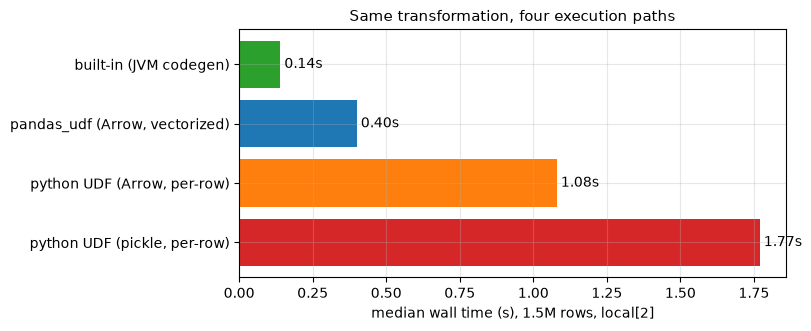

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(udf_bench.variant[::-1], udf_bench.median_s[::-1],
        color=["tab:red", "tab:orange", "tab:blue", "tab:green"])
for i, v in enumerate(udf_bench.median_s[::-1]):
    ax.text(v, i, f" {v:.2f}s", va="center")
ax.set_xlabel(f"median wall time (s), {N_ORDERS / 1e6:.1f}M rows, local[2]")
ax.set_title("Same transformation, four execution paths")
plt.show()

## 8. Pitfalls

Each one is a mistake that ships to production regularly; the first three are
demonstrated live below.

1. **Leaving `spark.sql.shuffle.partitions` at 200 for small data** — 200 tiny tasks
   whose scheduling overhead dwarfs the work. AQE's partition coalescing largely
   rescues you *when it's on*; know both facts.
2. **Unbounded `collect()` / `toPandas()`** — the driver is one process with one heap.
   Aggregate or `limit()` first; pull only what a human or a plot needs.
3. **UDF type mismatches fail silently** — declare `DoubleType` but return something
   else and Spark gives you `NULL`s, not an error. Silent nulls then flow into joins
   and aggregates.
4. **Recomputing shared lineage instead of caching** (section 6) — and its mirror
   image, caching everything "just in case".
5. **`coalesce(1)` to get one output file** (section 6) — collapses the whole final
   stage to one task.
6. **Non-determinism you didn't ask for**: `F.rand()` without a seed, `dropDuplicates`
   keeping an arbitrary row, `limit` without `orderBy`. Under task retries these can
   differ *within one job*. Seed everything; make dedup deterministic with a window
   ordered by an explicit tiebreaker.

In [22]:
# Pitfall 1: 200 shuffle partitions on local data (AQE off isolates the raw effect)
spark.conf.set("spark.sql.adaptive.enabled", "false")
def grp():
    orders.groupBy("customer_id").agg(F.sum("amount")).count()


spark.conf.set("spark.sql.shuffle.partitions", "200")
t_200, _ = spark_time(grp, reps=2)
spark.conf.set("spark.sql.shuffle.partitions", "8")
t_8, _ = spark_time(grp, reps=2)
spark.conf.set("spark.sql.adaptive.enabled", "true")
print(f"groupBy on {N_ORDERS / 1e6:.1f}M rows: 200 shuffle partitions {t_200:.2f}s vs "
      f"8 partitions {t_8:.2f}s ({t_200 / t_8:.1f}x) — pure task-scheduling overhead; "
      "AQE partition coalescing hides this when enabled")

groupBy on 1.5M rows: 200 shuffle partitions 2.14s vs 8 partitions 0.57s (3.7x) — pure task-scheduling overhead; AQE partition coalescing hides this when enabled


In [23]:
# Pitfall 2: driver discipline — aggregate in Spark, collect only the summary
approx_row_bytes = len(orders.limit(1000).toPandas().to_records(index=False).tobytes()) / 1000
est_mb = approx_row_bytes * N_ORDERS / 1e6
summary = orders.groupBy("channel").agg(
    F.count("*").alias("n"), F.round(F.avg("amount"), 2).alias("avg_amount")
).toPandas()  # 3 rows cross the wire, not 2M
print(f"orders.toPandas() would move ~{est_mb:.0f} MB into the single driver process;")
print(f"the aggregated summary is {len(summary)} rows:")
print(summary.to_string(index=False))

orders.toPandas() would move ~42 MB into the single driver process;
the aggregated summary is 3 rows:
channel      n  avg_amount
    web 499933       59.99
    app 500319       60.07
  store 499748       60.10


In [24]:
# Pitfall 3: wrong declared return type. The legacy pickled UDF -> silent NULLs;
# the Arrow-optimized UDF (Spark 4 default) fails loudly. Know which one your
# cluster runs — a lot of production Spark still silently nulls.
bad_pickle = F.udf(lambda a: "high" if a > 100 else "low", DoubleType(), useArrow=False)
n_null = (orders.select(bad_pickle("amount").alias("tier"))
          .filter(F.col("tier").isNull()).count())
print(f"pickled UDF, declared Double but returned str: {n_null:,} of {N_ORDERS:,} rows "
      "are NULL — no error raised, garbage flows downstream")

bad_arrow = F.udf(lambda a: "high" if a > 100 else "low", DoubleType(), useArrow=True)
sc.setLogLevel("FATAL")  # keep the expected executor error out of the console
try:
    # note the filter: a bare .count() would let Catalyst PRUNE the UDF column away
    # and never run it — itself a lesson in how aggressively plans are optimized
    (orders.select(bad_arrow("amount").alias("tier"))
     .filter(F.col("tier").isNull()).count())
    print("no exception — unexpected")
except Exception as err:
    print(f"Arrow-optimized UDF raised {type(err).__name__} instead "
          "('cannot parse string as double') — loud failure beats silent NULLs")
finally:
    sc.setLogLevel("ERROR")

pickled UDF, declared Double but returned str: 1,500,000 of 1,500,000 rows are NULL — no error raised, garbage flows downstream


Arrow-optimized UDF raised PythonException instead ('cannot parse string as double') — loud failure beats silent NULLs


## 9. Interview corner

**Q1. Walk me through what physically happens when you join two large tables.**
Neither fits in memory, so Spark picks sort-merge: both tables are shuffled —
hash-partitioned on the join key across the network — then each partition pair is
sorted and merged. Two full shuffles is the dominant cost; skewed keys concentrate in
single tasks; memory pressure spills sorts to disk. Mitigations, in order: filter and
aggregate before joining (reduce shuffled bytes), broadcast if either side is small (or
becomes small after filters), fix skew (AQE/salting), pre-bucket both tables on the join
key if this join recurs (bucketing eliminates the shuffle at read time).

**Q2. A job sits at 199/200 tasks for an hour. Diagnose and fix.**
One straggler task = one oversized partition = almost always **key skew** (or one bad
node). Confirm in the UI: max task duration and shuffle-read size ≫ median (our section
5 charts). Find the key: `df.groupBy(key).count().orderBy(desc)`. Whale keys are often
NULL/default sentinel values — consider handling them separately or dropping them.
Fixes: AQE skew-join (check it's on and thresholds fire), salting for the general case,
broadcast to avoid the shuffle entirely, or split whale-vs-rest and union. Speculative
execution helps only if the cause is a slow *node*, not a big *partition*.

**Q3. When do you broadcast, and what goes wrong?**
Broadcast when one side is small — default auto-threshold is 10 MB estimated, but with
an explicit hint tens-to-hundreds of MB is routine if executors have headroom. The big
side then never shuffles. Failure modes: OOM when the "small" side isn't (it must fit
in the driver *and* every executor, uncompressed), a dimension that grows until it
blows up months later, and stale size estimates making Spark auto-broadcast something
huge (that's a reason to *set* the threshold, not just raise it).

**Q4. Why are Python UDFs slow, and what's the escalation path?**
Data must leave the JVM: serialize → Python process → deserialize → call your function
(per row for classic UDFs) → back. Catalyst also treats the UDF as a black box — no
predicate pushdown, no column pruning through it, no codegen. Escalation: built-in
functions (JVM speed), then `pandas_udf` (Arrow + vectorized, needed for scipy/custom
Python), then Arrow-optimized UDF, and pickled UDFs last. Our benchmark: the pickled
UDF was an order of magnitude (~10-15x) slower than the built-in on the identical
computation.

**Q5. `repartition` vs `coalesce`?**
`repartition` = full shuffle: balances sizes, can increase count, can partition by key;
use before heavy parallel work or to fix skewed file sizes. `coalesce` = narrow merge:
cheap way to reduce output file count, but it collapses upstream parallelism in the
same stage — `coalesce(1)` after heavy compute single-threads the compute itself.

**Q6. When would you cache, and when is it a mistake?**
Cache when an expensive lineage is consumed by 2+ actions and fits your memory budget
(ML iterations, branching DAGs, exploration). Mistakes: caching single-use data (pay
materialization for nothing), caching giant raw tables that evict useful blocks, and
forgetting `unpersist()`. Also remember caching is an optimization barrier — filters
won't push below the cached relation.

**Q7. What does AQE actually do?**
Re-plans at shuffle boundaries using observed statistics: coalesces small shuffle
partitions (makes static `shuffle.partitions` tuning mostly obsolete), converts
sort-merge to broadcast when a side turns out small, splits skewed join partitions.
It doesn't fix skewed windows/aggregations, bad UDFs, or an avoidable shuffle you wrote.

**Q8. Would you use Spark for a 30 GB daily aggregation job?**
Interrogate the requirement first: 30 GB fits one machine — DuckDB/Polars will likely
be faster end-to-end and 10x simpler to operate. Spark wins if the data is already in a
lakehouse with Spark infra, the job must scale elastically, or it's one step in a
distributed pipeline. Saying "no Spark needed" with reasons *is* the senior answer.

## 10. Key takeaways

- Spark is a TB-scale / existing-lakehouse tool; below ~100 GB a single machine with
  DuckDB/Polars is usually faster to run *and* to build. Lead with sizing.
- Transformations are lazy; actions trigger jobs; jobs split into stages **at shuffle
  boundaries**; stages run one task per partition. "Slow job" debugging = "which stage,
  which task, why".
- Count the `Exchange` nodes in `.explain()` — that's your shuffle count. Wide ops
  (`join`, `groupBy`, `distinct`, `orderBy`, `Window.partitionBy`, `repartition`) shuffle;
  narrow ops pipeline.
- Broadcast joins avoid shuffling the big table entirely — the single highest-leverage
  join optimization when one side is small. AQE can do it for you at runtime.
- Skew ⇒ stragglers: after a shuffle, one whale key = one giant task (our demo: one
  partition held ~90% of rows and ran an order of magnitude longer than the median
  task). Fixes:
  AQE skew-join, salting (exact same results, work spread over S sub-keys), broadcast,
  or handle the whale key separately — it's often garbage anyway.
- Map-side partial aggregation means plain `groupBy().sum()` tolerates skew; joins,
  windows, and `collect_list` do not.
- `coalesce` is narrow and can swallow upstream parallelism; `repartition` shuffles.
  Cache only what is reused; `unpersist` when done.
- UDF ladder: built-ins ≫ `pandas_udf` > Arrow UDF > pickled UDF (an order-of-magnitude
  spread in our benchmark) — and UDFs blind the optimizer on top of the serialization
  cost.
- Local-mode timings understate every distributed cost, especially shuffles. Treat all
  numbers here as directional.

## 11. Exercises

**Exercise 1 — phrasebook fluency.** Using `events` and `users` (sections 3):
compute, per `country` and per `event_type`, the number of events and total `value`,
keeping only (country, event_type) pairs with at least 1,000 events, ordered by total
value descending. Write it twice: DataFrame API and Spark SQL. Verify they match each
other and pandas.

**Exercise 2 — count the shuffles.** *Before running it*, predict how many `Exchange`
nodes the plan of this query has (AQE and auto-broadcast disabled):
`orders.join(customers, "customer_id").groupBy("region").agg(F.avg("amount")).orderBy("region")`.
Then check with `.explain()`, and explain how the count changes with a broadcast hint.

**Exercise 3 — kill the UDF.** The pickled UDF below assigns a spend tier per order.
Rewrite it with built-in expressions only, prove the outputs are identical, and measure
the speedup.

In [25]:
# --- Solution 1 ---------------------------------------------------------------
sol1_df = (
    events.join(users, "user_id")
    .groupBy("country", "event_type")
    .agg(F.count("*").alias("n_events"), F.round(F.sum("value"), 2).alias("total_value"))
    .filter(F.col("n_events") >= 1000)
    .orderBy(F.desc("total_value"))
)
sol1_sql = spark.sql("""
    SELECT u.country, e.event_type,
           COUNT(*)              AS n_events,
           ROUND(SUM(e.value), 2) AS total_value
    FROM events e JOIN users u USING (user_id)
    GROUP BY u.country, e.event_type
    HAVING COUNT(*) >= 1000
    ORDER BY total_value DESC
""")
assert sol1_df.collect() == sol1_sql.collect()

sol1_pandas = (
    events_pd.merge(users_pd, on="user_id")
    .groupby(["country", "event_type"], as_index=False)
    .agg(n_events=("value", "size"), total_value=("value", "sum"))
    .query("n_events >= 1000")
)
sol1_out = sol1_df.toPandas()
merged = sol1_out.merge(sol1_pandas, on=["country", "event_type"], suffixes=("_sp", "_pd"))
assert len(merged) == len(sol1_out) == len(sol1_pandas)
assert (merged.n_events_sp == merged.n_events_pd).all()
assert np.allclose(merged.total_value_sp, merged.total_value_pd.round(2))
print(f"DataFrame API == SQL == pandas ({len(sol1_out)} groups):")
print(sol1_out.head(5).to_string(index=False))

DataFrame API == SQL == pandas (8 groups):
country event_type  n_events  total_value
     US       view     21724    652567.13
     DE       view     12024    361305.73
     GB       view      9868    294701.42
     BR       view      4380    128920.55
     US       cart      4163    126679.48


In [26]:
# --- Solution 2 ---------------------------------------------------------------
# Prediction: 4 Exchanges. Join shuffles BOTH sides by customer_id (2); groupBy("region")
# re-shuffles by region because data is partitioned by customer_id (1); orderBy is a
# range repartition (1). With a broadcast hint, the two join Exchanges disappear -> 2.
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

ex2 = (orders.join(customers, "customer_id")
       .groupBy("region").agg(F.avg("amount")).orderBy("region"))
ex2_bc = (orders.join(F.broadcast(customers), "customer_id")
          .groupBy("region").agg(F.avg("amount")).orderBy("region"))
n_ex, n_ex_bc = plan_of(ex2).count("Exchange"), plan_of(ex2_bc).count("Exchange")
print(f"sort-merge version: {n_ex} Exchanges (2 join + 1 groupBy + 1 orderBy)")
print(f"broadcast version : {n_ex_bc} Exchanges (BroadcastExchange is not a shuffle of "
      "the fact table; only groupBy + orderBy shuffle remain)")

spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10MB")

sort-merge version: 4 Exchanges (2 join + 1 groupBy + 1 orderBy)
broadcast version : 3 Exchanges (BroadcastExchange is not a shuffle of the fact table; only groupBy + orderBy shuffle remain)


In [27]:
# --- Solution 3 ---------------------------------------------------------------
def tier_py(amount):
    if amount is None:
        return None
    if amount >= 150:
        return "high"
    if amount >= 50:
        return "mid"
    return "low"


tier_udf = F.udf(tier_py, "string", useArrow=False)
tier_builtin = (
    F.when(F.col("amount") >= 150, "high")
    .when(F.col("amount") >= 50, "mid")
    .otherwise("low")
)

udf_counts = sorted(orders.groupBy(tier_udf("amount").alias("tier")).count().collect())
builtin_counts = sorted(orders.groupBy(tier_builtin.alias("tier")).count().collect())
assert udf_counts == builtin_counts

# Benchmarking trap: rebuild the query INSIDE the lambda. Re-collecting the same
# DataFrame object reuses its shuffle outputs and skips the map stage (where the UDF
# runs), which makes the UDF look free.
t_udf, _ = spark_time(
    lambda: orders.groupBy(tier_udf("amount").alias("tier")).count().collect(), reps=2)
t_builtin, _ = spark_time(
    lambda: orders.groupBy(tier_builtin.alias("tier")).count().collect(), reps=2)
print("identical tier distributions:", builtin_counts)
print(f"pickled UDF {t_udf:.2f}s vs F.when chain {t_builtin:.2f}s "
      f"-> {t_udf / t_builtin:.1f}x faster, and Catalyst can now see the logic")

identical tier distributions: [Row(tier='high', count=122917), Row(tier='low', count=846503), Row(tier='mid', count=530580)]
pickled UDF 1.40s vs F.when chain 0.24s -> 5.9x faster, and Catalyst can now see the logic


In [28]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
